# ARTI 502 - Deep Learning: 2nd Assignment
### Training-Testing CNN with CIFAR Dataset using PyTorch

---
# Task 1: Getting the CIFAR Dataset

### Instructions
- Download/load the CIFAR dataset using PyTorch.
- Set `DATA_PATH` to a directory where the dataset will be downloaded.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms

: 

In [2]:
DATA_PATH = './data'
transform = transforms.ToTensor()

In [3]:
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 170M/170M [00:17<00:00, 9.51MB/s]


In [4]:
print('CIFAR-10 dataset loaded successfully!')
print('Number of training images:', len(train_dataset))
print('Number of test images:', len(test_dataset))

CIFAR-10 dataset loaded successfully!
Number of training images: 50000
Number of test images: 10000


---
# Task 2: Defining the Network

### Instructions
- Define the CNN architecture using convolutional and maxpooling layers.
- Create training and test functions.


#### 2.1 Define CNN Architecture
We'll use two convolutional layers, two max pooling layers and two fully connected layers

In [5]:
import torch.nn as nn
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


#### 2.2 Training Function

In [6]:
def train(model, train_loader, criterion, optimizer):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        images,labels = images.to(device),labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() *images.size(0)

    return total_loss / len(train_loader.dataset)

#### 2.3 Testing Function

In [7]:
def test(model, test_loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels= images.to(device),labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()

    return total_loss / len(test_loader.dataset), correct / len(test_loader.dataset)

---
# Task 3: Loading Data

### Instructions
- Find the images tensor size.
- Visualize the images using matplotlib.



### 3.1 Images Tensor Size
Use a DataLoader to get one batch of CIFAR-10 images and print its size.

In [8]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
images, labels = next(iter(train_loader))

print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)

Images tensor size: torch.Size([64, 3, 32, 32])
Labels tensor size: torch.Size([64])


### 3.2 Visualize CIFAR-10 Images
Display some images from the batch using matplotlib.

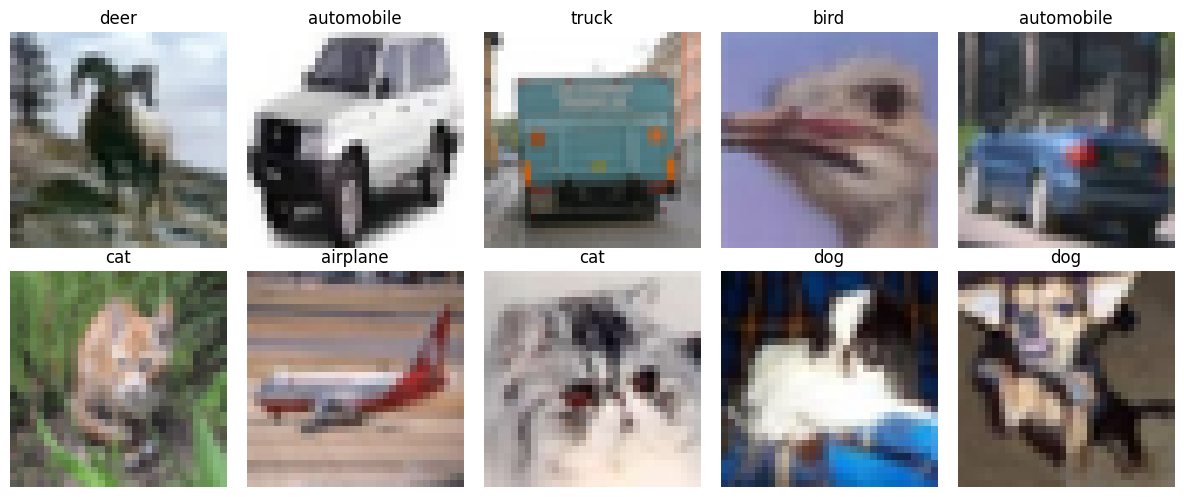

In [9]:
import matplotlib.pyplot as plt

class_names = train_dataset.classes

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1, 2, 0))
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

---
# Task 4: Dataset Augmentation

Suggested augmentations include ToPILImage, RandomHorizontalFlip, RandomResizedCrop, ColorJitter, RandomRotation, Normalize, noise, and ToTensor.



In [10]:
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

class AddGaussianNoise:
    def __init__(self, mean=0.0, std=0.03):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std + self.mean
        return torch.clamp(tensor + noise, 0.0, 1.0)

train_transform_augmented = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomResizedCrop(size=32, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    AddGaussianNoise(std=0.03),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset_augmented = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=train_transform_augmented
)

test_dataset_augmented = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform
)

train_loader = DataLoader(train_dataset_augmented, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset_augmented, batch_size=64, shuffle=False)

print("Augmented training dataset loaded:", len(train_dataset_augmented))
print("Test dataset loaded:", len(test_dataset_augmented))

Augmented training dataset loaded: 50000
Test dataset loaded: 10000


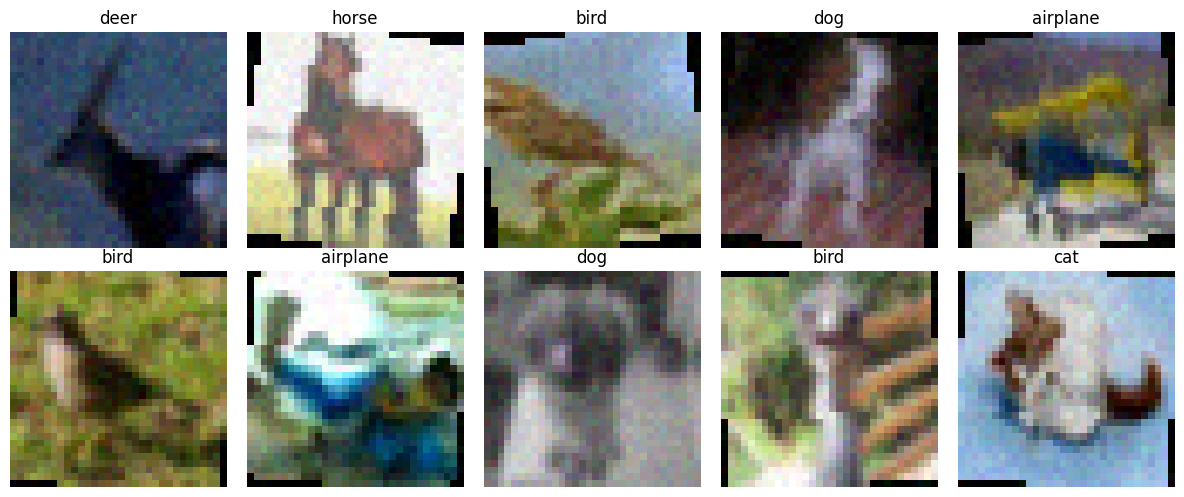

In [11]:
class_names = train_dataset_augmented.classes

images_aug, labels_aug = next(iter(train_loader))

def unnormalize(image):
    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)
    return torch.clamp(image * std_tensor + mean_tensor, 0, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = unnormalize(images_aug[i])
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[labels_aug[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

---
# Task 5: Training Function and Tuning Hyperparameters

### Instructions
- Record and plot training loss.
- Record and plot test loss.
- Record and plot test accuracy.
- Experiment with architectures and hyperparameters.




Experiment: Original CNN - LR 0.001
Epoch [1/5] Train Loss: 1.4624 | Test Loss: 1.1507 | Test Accuracy: 58.87%
Epoch [2/5] Train Loss: 1.1739 | Test Loss: 1.0034 | Test Accuracy: 64.83%
Epoch [3/5] Train Loss: 1.0639 | Test Loss: 0.9717 | Test Accuracy: 66.05%
Epoch [4/5] Train Loss: 0.9953 | Test Loss: 0.9198 | Test Accuracy: 68.53%
Epoch [5/5] Train Loss: 0.9480 | Test Loss: 0.8944 | Test Accuracy: 69.66%

Final Results:
Train Loss: 0.9480
Test Loss: 0.8944
Test Accuracy: 69.66%

Experiment: Original CNN - LR 0.0005
Epoch [1/5] Train Loss: 1.5309 | Test Loss: 1.2366 | Test Accuracy: 56.13%
Epoch [2/5] Train Loss: 1.2552 | Test Loss: 1.0991 | Test Accuracy: 60.88%
Epoch [3/5] Train Loss: 1.1357 | Test Loss: 0.9812 | Test Accuracy: 65.49%
Epoch [4/5] Train Loss: 1.0562 | Test Loss: 0.9025 | Test Accuracy: 68.11%
Epoch [5/5] Train Loss: 0.9985 | Test Loss: 0.8925 | Test Accuracy: 68.39%

Final Results:
Train Loss: 0.9985
Test Loss: 0.8925
Test Accuracy: 68.39%

Experiment: Deeper CNN -

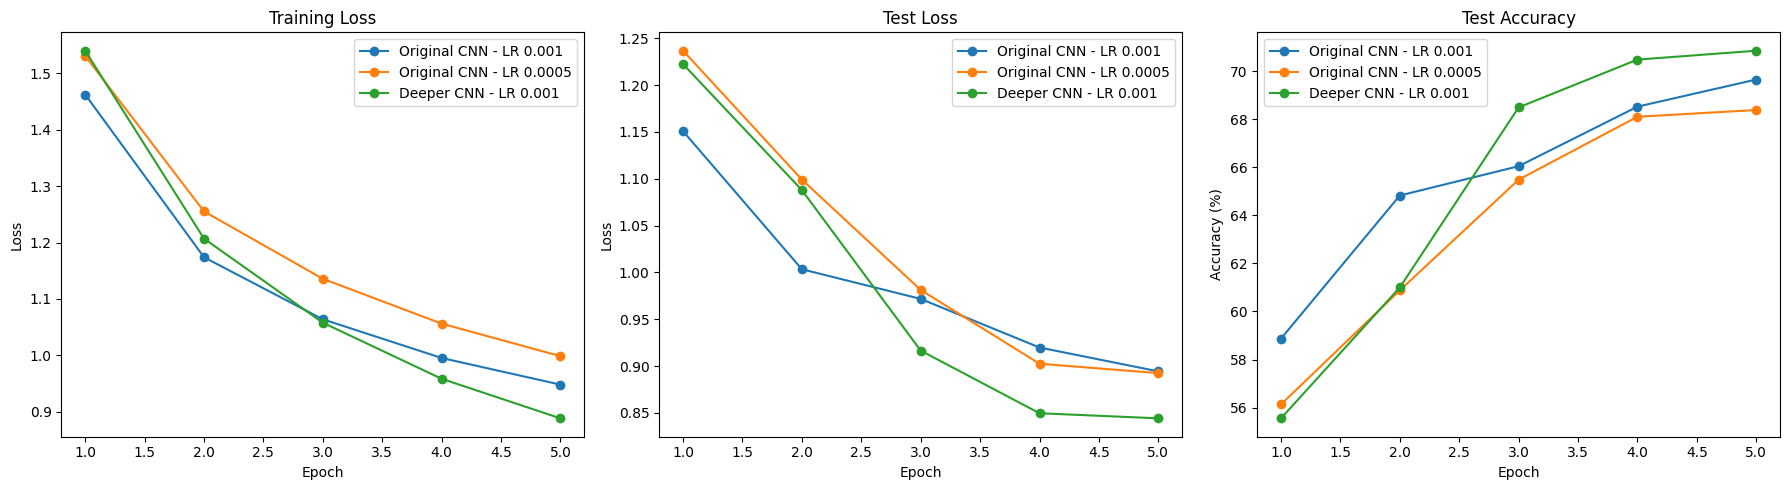


FINAL COMPARISON

Original CNN - LR 0.001
Train Loss: 0.9480
Test Loss: 0.8944
Test Accuracy: 69.66%

Original CNN - LR 0.0005
Train Loss: 0.9985
Test Loss: 0.8925
Test Accuracy: 68.39%

Deeper CNN - LR 0.001
Train Loss: 0.8883
Test Loss: 0.8442
Test Accuracy: 70.86%


In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# ==========================================
# 1. Training Function
# ==========================================

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(train_loader)


# ==========================================
# 2. Evaluation Function
# ==========================================

def evaluate(model, test_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / len(test_loader)
    accuracy = 100 * correct / total

    return test_loss, accuracy


# ==========================================
# 3. Second CNN Architecture
# ==========================================

class DeeperCNN(nn.Module):
    def __init__(self):
        super(DeeperCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# ==========================================
# 4. Experiments Configuration
# ==========================================

experiments = [
    {
        "name": "Original CNN - LR 0.001",
        "model": CNN,
        "lr": 0.001,
        "epochs": 5
    },
    {
        "name": "Original CNN - LR 0.0005",
        "model": CNN,
        "lr": 0.0005,
        "epochs": 5
    },
    {
        "name": "Deeper CNN - LR 0.001",
        "model": DeeperCNN,
        "lr": 0.001,
        "epochs": 5
    }
]
# ==========================================
# 5. Training and Comparing Experiments
# ==========================================

all_results = {}

for experiment in experiments:

    print("\n" + "=" * 50)
    print("Experiment:", experiment["name"])
    print("=" * 50)

    model = experiment["model"]().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=experiment["lr"]
    )

    history = {
        "train_loss": [],
        "test_loss": [],
        "test_accuracy": []
    }

    for epoch in range(experiment["epochs"]):

        train_loss = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        test_loss, test_accuracy = evaluate(
            model, test_loader, criterion, device
        )

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch [{epoch + 1}/{experiment['epochs']}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Accuracy: {test_accuracy:.2f}%"
        )

    all_results[experiment["name"]] = history

    print("\nFinal Results:")
    print(f"Train Loss: {history['train_loss'][-1]:.4f}")
    print(f"Test Loss: {history['test_loss'][-1]:.4f}")
    print(f"Test Accuracy: {history['test_accuracy'][-1]:.2f}%")


# ==========================================
# 6. Plot Results
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name, history in all_results.items():

    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(
        epochs, history["train_loss"], marker="o", label=name
    )

    axes[1].plot(
        epochs, history["test_loss"], marker="o", label=name
    )

    axes[2].plot(
        epochs, history["test_accuracy"], marker="o", label=name
    )


axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Test Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

axes[2].set_title("Test Accuracy")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy (%)")
axes[2].legend()

plt.tight_layout()
plt.show()


# ==========================================
# 7. Compare Final Results
# ==========================================

print("\nFINAL COMPARISON")

for name, history in all_results.items():
    print(f"\n{name}")
    print(f"Train Loss: {history['train_loss'][-1]:.4f}")
    print(f"Test Loss: {history['test_loss'][-1]:.4f}")
    print(f"Test Accuracy: {history['test_accuracy'][-1]:.2f}%")